# Exploratory Notebook

## Setup

In [70]:
# Imports
from pathlib import Path
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

PROJECT_ROOT = Path.cwd().parent
RAW_PATH = PROJECT_ROOT/"data"/"raw"/"booking.csv"
PROCESSED_DIR = PROJECT_ROOT/"data"/"processed"

In [71]:
# Load dataset
df = pd.read_csv(RAW_PATH)
df.shape

(36285, 17)

Dataset loading correctly

## Inspection

In [72]:
df.head()

,Booking_ID,number of adults,number of children,number of weekend nights,number of week nights,type of meal,car parking space,room type,lead time,market segment type,repeated,P-C,P-not-C,average price,special requests,date of reservation,booking status
0,INN00001,1,1,2,5,Meal Plan 1,0,Room_Type 1,224,Offline,0,0,0,88.00,0,10/2/2015,Not_Canceled
1,INN00002,1,0,1,3,Not Selected,0,Room_Type 1,5,Online,0,0,0,106.68,1,11/6/2018,Not_Canceled
2,INN00003,2,1,1,3,Meal Plan 1,0,Room_Type 1,1,Online,0,0,0,50.00,0,2/28/2018,Canceled
3,INN00004,1,0,0,2,Meal Plan 1,0,Room_Type 1,211,Online,0,0,0,100.00,1,5/20/2017,Canceled
4,INN00005,1,0,1,2,Not Selected,0,Room_Type 1,48,Online,0,0,0,77.00,0,4/11/2018,Canceled


In [73]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 36285 entries, 0 to 36284
Data columns (total 17 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Booking_ID                36285 non-null  str    
 1   number of adults          36285 non-null  int64  
 2   number of children        36285 non-null  int64  
 3   number of weekend nights  36285 non-null  int64  
 4   number of week nights     36285 non-null  int64  
 5   type of meal              36285 non-null  str    
 6   car parking space         36285 non-null  int64  
 7   room type                 36285 non-null  str    
 8   lead time                 36285 non-null  int64  
 9   market segment type       36285 non-null  str    
 10  repeated                  36285 non-null  int64  
 11  P-C                       36285 non-null  int64  
 12  P-not-C                   36285 non-null  int64  
 13  average price             36285 non-null  float64
 14  special requests 

Strings, integers and floats

In [74]:
# 
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Booking_ID,36285,36285,INN00001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
number of adults,36285.0,NaN,NaN,NaN,1.844839,0.518813,0.0,2.0,2.0,2.0,4.0
number of children,36285.0,NaN,NaN,NaN,0.10536,0.402704,0.0,0.0,0.0,0.0,10.0
number of weekend nights,36285.0,NaN,NaN,NaN,0.810693,0.87059,0.0,0.0,1.0,2.0,7.0
number of week nights,36285.0,NaN,NaN,NaN,2.204602,1.410946,0.0,1.0,2.0,3.0,17.0
type of meal,36285,4,Meal Plan 1,27842,NaN,NaN,NaN,NaN,NaN,NaN,NaN
car parking space,36285.0,NaN,NaN,NaN,0.030977,0.173258,0.0,0.0,0.0,0.0,1.0
room type,36285,7,Room_Type 1,28138,NaN,NaN,NaN,NaN,NaN,NaN,NaN
lead time,36285.0,NaN,NaN,NaN,85.239851,85.938796,0.0,17.0,57.0,126.0,443.0
market segment type,36285,5,Online,23221,NaN,NaN,NaN,NaN,NaN,NaN,NaN


- Booking ID will likely have to go 
- Most common value for booking_status is Not Cancelled at 24396/36285 values. Roughly 1//3 cancelled so inbalanced data but this is to be expected. Implications: use class weights and threshold tuning, don't judge models on accuracy also
- For lead_time, mean () is well above median () but standard deviation is similar to mean (). All indicates right skew. Max is 443 days and 243 bookings were made more than a year ahead. This is probably a strong predictor. Tree models won't need a trabsform but logistic regression would benefit from logging.
- average_price: max of 540 is far from 75th percentile of 120. Looking at some outliers here potentially. 
- number_of_children: 75th percnetile is 0 but max is 10. Data entry error? Look at distribution.
- number_of_week nights: max is 17 while median is 2. Long stays are rare but do happen.
- number_of_adults: min is 0. Hotel booking without an adult doesn't make any sense. 
- nights: both night columns ahve a min of 0. Some hotel stays apparently have 0 nights?

In [75]:
df.nunique().sort_values()

car parking space               2
repeated                        2
booking status                  2
type of meal                    4
market segment type             5
number of adults                5
number of children              6
special requests                6
room type                       7
number of weekend nights        8
P-C                             9
number of week nights          18
P-not-C                        59
lead time                     352
date of reservation           553
average price                3930
Booking_ID                  36285
dtype: int64

- some binary variables 
- some ordinal and one-hot endcoding will be needed
- features with more unique values but not outrageous values (like number of weekend nights) are numerical
- make sure to parse dates correctly. maybe make features like month and day_of_week for booking

## Standardise Column Names

In [76]:
df = df.rename(columns={
    "Booking_ID": "booking_id",
    "number of adults": "n_adults",
    "number of children": "n_children",
    "number of weekend nights": "n_weekend_nights",
    "number of week nights": "n_week_nights",
    "type of meal": "meal_type",
    "car parking space": "car_parking_space",
    "room type": "room_type",
    "lead time": "lead_time",
    "market segment type": "market_segment",
    "repeated": "repeated_guest",
    "P-C": "prev_cancellations",
    "P-not-C": "prev_not_cancelled",
    "average price": "avg_price",
    "special requests": "n_special_requests",
    "date of reservation": "reservation_date",
    "booking status": "booking_status",
})


Will help when modularising things later

## Data Quality Checks

In [77]:
print("Nulls:\n", df.isna().sum()[lambda s: s > 0])
print("Full duplicates:", df.duplicated().sum())
print("Duplicates ignoring ID:", df.drop(columns="booking_id").duplicated().sum())

# Find unparsable dates
parsed = pd.to_datetime(df["reservation_date"], format="%m/%d/%Y", errors="coerce")
print("Bad dates:", parsed.isna().sum(), df.loc[parsed.isna(), "reservation_date"].unique())

# Suspicious records
total_nights = df["n_weekend_nights"] + df["n_week_nights"]
print("Zero nights:", (total_nights == 0).sum())
print("Zero adults:", (df["n_adults"] == 0).sum())
print("Zero price:\n", df.loc[df["avg_price"] == 0, "market_segment"].value_counts())

Nulls:
 Series([], dtype: int64)
Full duplicates: 0
Duplicates ignoring ID: 10276
Bad dates: 37 <ArrowStringArray>
['2018-2-29']
Length: 1, dtype: str
Zero nights: 78
Zero adults: 139
Zero price:
 market_segment
Complementary    354
Online           191
Name: count, dtype: int64


- No full duplicates. Some are the same but that's because of group bookings most likely. Keep them and use a group aware split
- A bad date that doesn't exist that eneds to be removed '2018-2-29'
- 78 records have 0 nights. They also have 0 price. Could be complimentary, do not assume bad data
- 139 records have 0 adults but they've also got children. Kids aren't amking bookings so likely adults being recorded as children. Note as a quirk but don't delete the rows. 
- 545 rows have 0 price. However, there is a whole market segment for Complimentary so do not treat 0 as missing.

Conclusion: only drop the 37 rows with bad dates. Could also use a group aware split (give identical rows the same group ID)

## Target Distribution

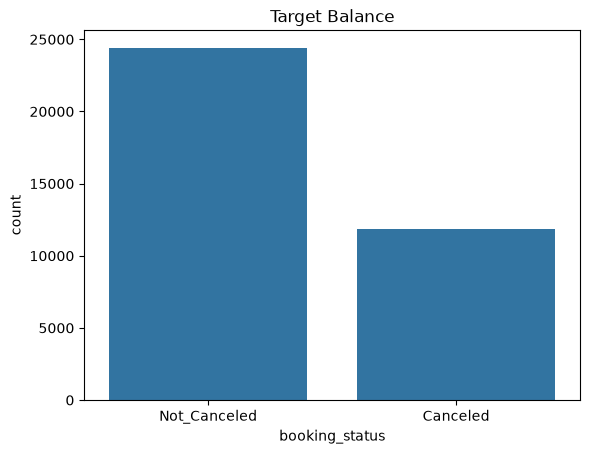

In [78]:
df["booking_status"].value_counts(normalize=True)
sns.countplot(data=df, x="booking_status");plt.title("Target Balance"); plt.show()

Somewhat imbalanced data. 

## Univariate EDA

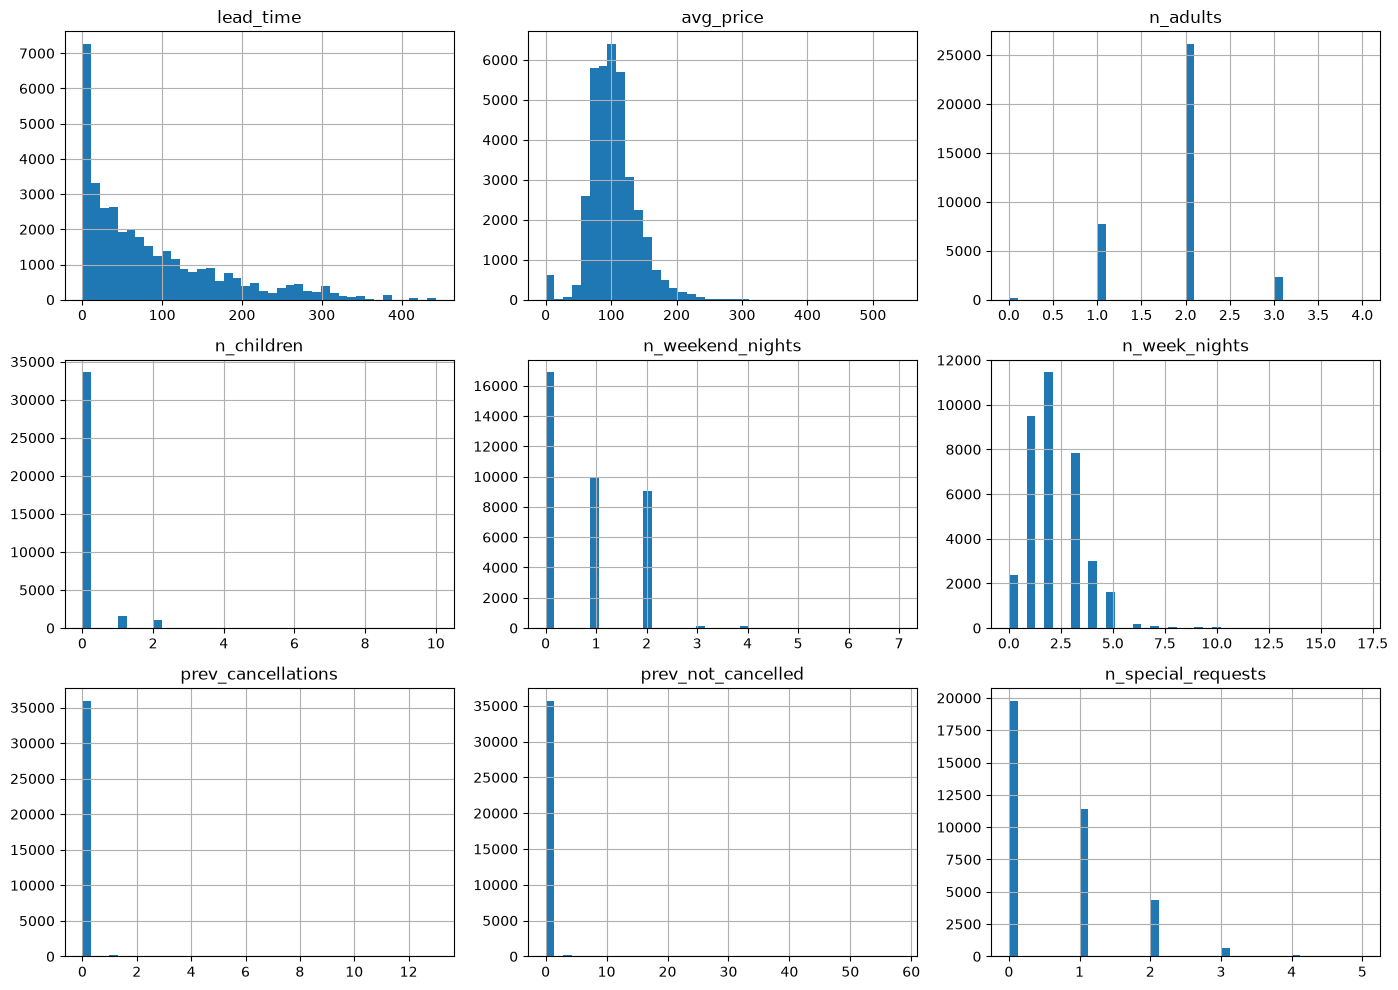

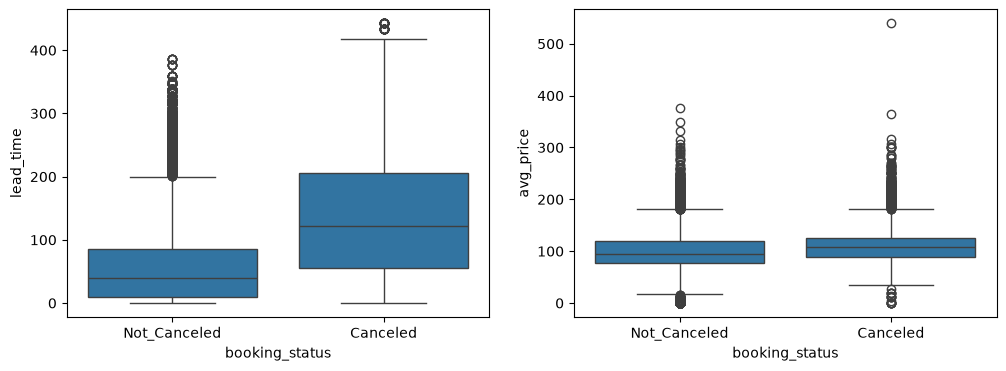

In [79]:
num_cols = ["lead_time", "avg_price", "n_adults", "n_children",
            "n_weekend_nights", "n_week_nights", "prev_cancellations",
            "prev_not_cancelled", "n_special_requests"]
cat_cols = ["meal_type", "room_type", "market_segment",
            "car_parking_space", "repeated_guest"]

df[num_cols].hist(bins=40, figsize=(14, 10)); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x="booking_status", y="lead_time", ax=axes[0])
sns.boxplot(data=df, x="booking_status", y="avg_price", ax=axes[1])
plt.show()

- lead_time is right skewed with a big spike at 0
- av_price is slightly right skewed with 100 being most common
- n_adults is most commonly 2 by far
- n_children is most commonly 0 by far
- n_weekend nights is usually 0 but 1 or 2 are also common. would expect a drop around 3+ as it indicates much longer stay. This is indeed visible
- Usually at least some week nights, most commonly 1, 2 or 3
- Mode for previous cancellations is 0 by a huge margin
- prev_not_cancelled is also 0 for mode by a huge way
- Most people have no special requests but 1 is common, 2 not unusual. Some have 3 but much less common. 
- The median lead_time for the cancelled group is noticably higher than the not cancelled group. Cancelled doesn't ahve many outliers.
- The median avg_price for cancelled and not cancelled are essentially the same so price doesn't appear to have as much of an effect

## Cancellation by Category

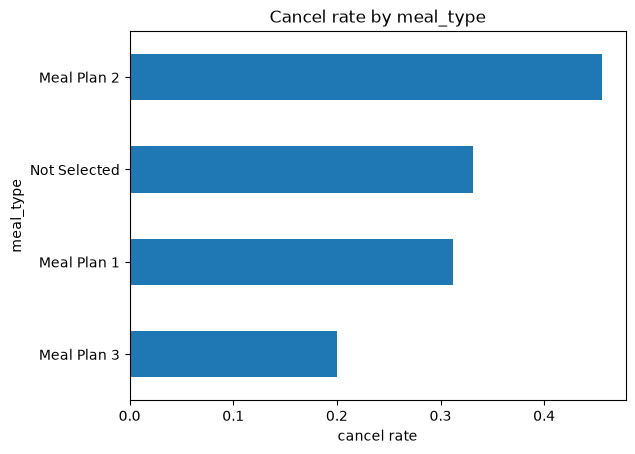

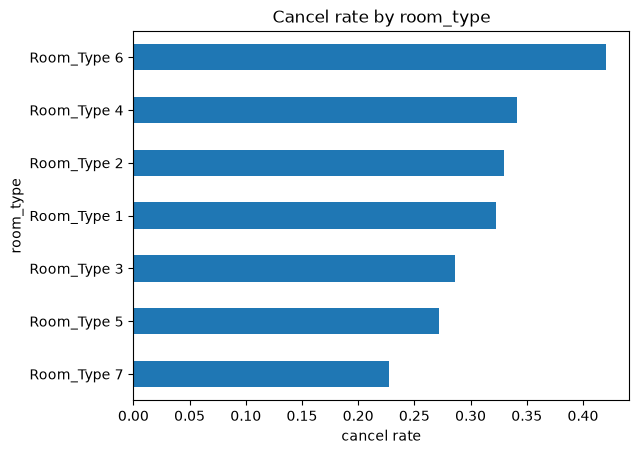

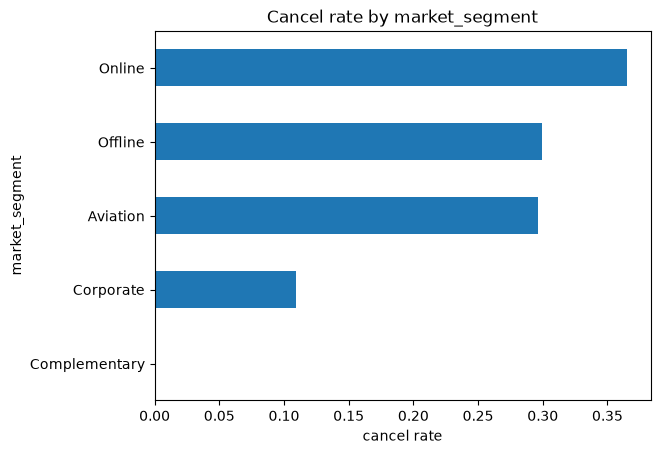

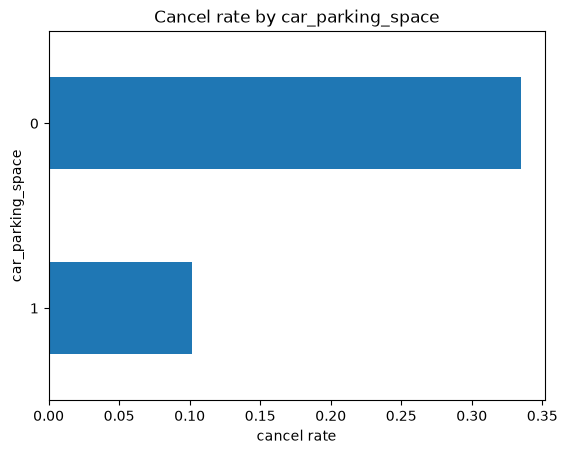

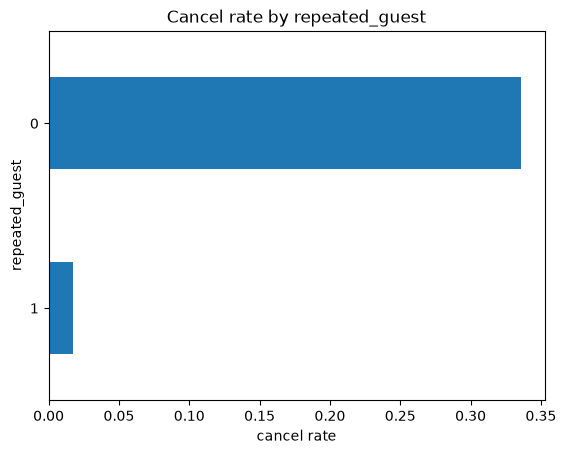

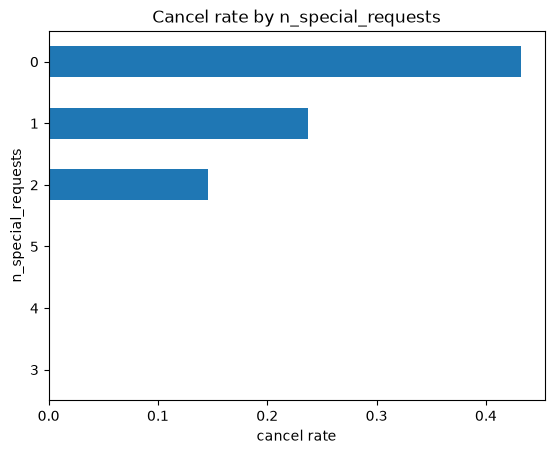

In [80]:
y_bin = (df["booking_status"] == "Canceled").astype(int)
for col in cat_cols + ["n_special_requests"]:
    rate = y_bin.groupby(df[col]).mean().sort_values()
    rate.plot(kind="barh", title=f"Cancel rate by {col}"); plt.xlabel("cancel rate"); plt.show()

- Repeated guests way less likely to cancel
- Cancellations fall sharply as special requests go up. To be expected.
- People less likely to cancel is they have car parking
- Nobody cancels when it's complimentary. About 1/3 of canecllations are online but offline and aviation aren;t far behind. 
- Varies by room type and meal type but nothing massive.

## Cleaning

In [81]:
# Drop booking ID because it's useless
df = df.drop(columns="booking_id")

# Get rid of the dodgy dates
df["reservation_date"] = pd.to_datetime(df["reservation_date"], format="%m/%d/%Y", errors="coerce")
df = df.dropna(subset=["reservation_date"]) # Get rid of the 37 invalid '2018-2-29' rows
df = df.reset_index(drop=True)

df.shape

(36248, 16)

Shape looks correct. Duplicates, zero-night, zero-adult and zero-price rows were kept on prupose because they're all plausible or because of likely data entry errors

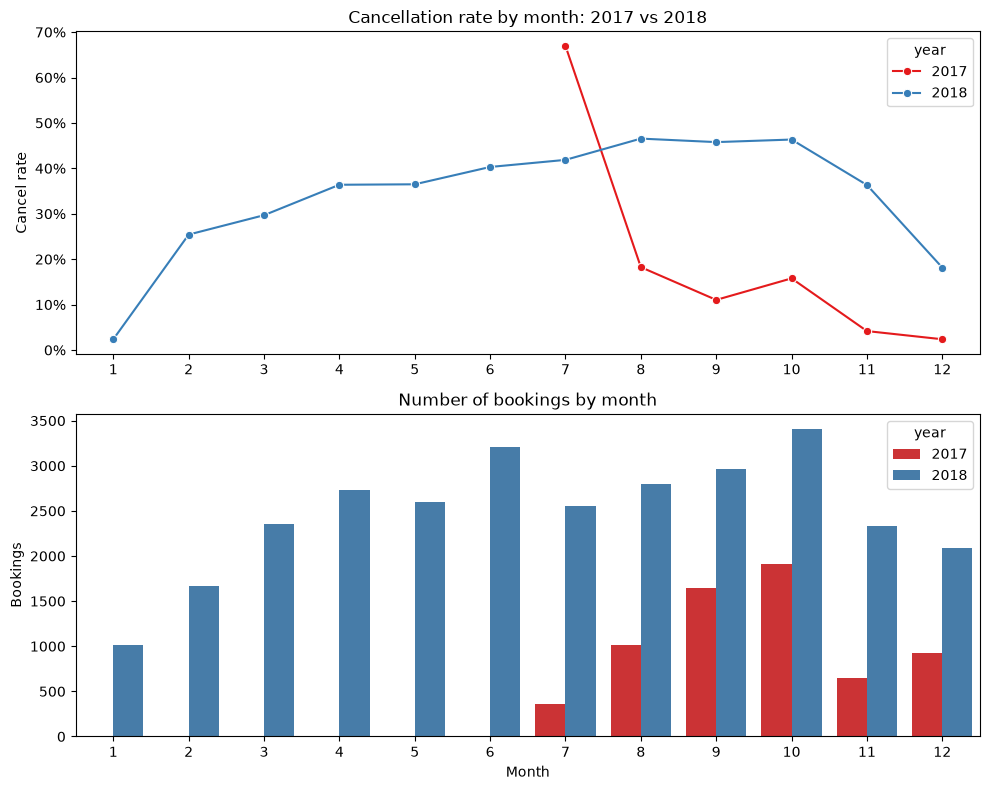

In [82]:
# Cancellation rate by month, 2017 vs 2018 (the single 2015/2016 rows are excluded)
plot_df = df.assign(
    year=df["reservation_date"].dt.year,
    month=df["reservation_date"].dt.month,
    cancelled=(df["booking_status"] == "Canceled").astype(int),
).query("year in [2017, 2018]")

monthly = plot_df.groupby(["year", "month"])["cancelled"].agg(rate="mean", n="size").reset_index()
monthly_rates = monthly.query("n >= 30")   # hide rates based on too few bookings (e.g. May 2017 = 1 booking)

fig, axes = plt.subplots(2, 1, figsize=(10, 8))

sns.lineplot(data=monthly_rates, x="month", y="rate", hue="year", marker="o", palette="Set1", ax=axes[0])
axes[0].set_title("Cancellation rate by month: 2017 vs 2018")
axes[0].set_ylabel("Cancel rate")
axes[0].set_xlabel("")
axes[0].set_xticks(range(1, 13))
axes[0].set_xlim(0.5, 12.5)
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))

sns.barplot(data=monthly, x="month", y="n", hue="year", palette="Set1", ax=axes[1])
axes[1].set_title("Number of bookings by month")
axes[1].set_ylabel("Bookings")
axes[1].set_xlabel("Month")

plt.tight_layout()
plt.show()


Noticed (see further down in the notebook. This is put here because it's before reservation_date is dropped) that cancelattions are seasonal. In 2018 they rise from 2% in Jan to around 46% in Aug-Oct, then fall to 18% in Dec. Data from 2017 only covers July to Dec. Apart from July (67%), 2017 cancellations are far lower (2-18%) than in same months of 2018. Behaviour shifted over time. Year should be excluded as a feature but month should be kept to capture seasonality. A time-based holdout should be done to check how model copes with drift. Means drift monitoring will be important after deployment.

## Feature Engineering

In [83]:
# Combined features
df["total_nights"] = df["n_weekend_nights"] + df["n_week_nights"]
df["total_guests"] = df["n_adults"] + df["n_children"]

# Date features like month and day of week resevation was made
df["res_month"] = df["reservation_date"].dt.month
df["res_daysofweek"] = df["reservation_date"].dt.dayofweek
df = df.drop(columns="reservation_date")

# Group rare categories (5 and 7 rows respectively)
df["meal_type"] = df["meal_type"].replace({"Meal Plan 3": "Other"})
df["room_type"] = df["room_type"].replace({"Room_Type 3": "Room_Type Other"})

# Cap special requests at 3 (3, 4, 5 all have 0% cancellations)
df["n_special_requests"] = df["n_special_requests"].clip(upper=3)

C:\Users\charl\AppData\Local\Temp\ipykernel_37736\1131136938.py:7: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["res_daysofweek"] = df["reservation_date"].dt.dayofweek


## Encoding

In [84]:
df["booking_status"] = (df["booking_status"] == "Canceled").astype(int)

df = pd.get_dummies(df, columns=["meal_type", "room_type", "market_segment"], drop_first=True)
bool_cols = df.select_dtypes(include="bool").columns
df[bool_cols] = df[bool_cols].astype(int)

df.info()
df["booking_status"].mean()   # expect ~0.328

<class 'pandas.DataFrame'>
RangeIndex: 36248 entries, 0 to 36247
Data columns (total 29 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   n_adults                      36248 non-null  int64  
 1   n_children                    36248 non-null  int64  
 2   n_weekend_nights              36248 non-null  int64  
 3   n_week_nights                 36248 non-null  int64  
 4   car_parking_space             36248 non-null  int64  
 5   lead_time                     36248 non-null  int64  
 6   repeated_guest                36248 non-null  int64  
 7   prev_cancellations            36248 non-null  int64  
 8   prev_not_cancelled            36248 non-null  int64  
 9   avg_price                     36248 non-null  float64
 10  n_special_requests            36248 non-null  int64  
 11  booking_status                36248 non-null  int64  
 12  total_nights                  36248 non-null  int64  
 13  total_guests

np.float64(0.32779739571838445)

In [85]:
assert df.isna().sum().sum() == 0
assert df.select_dtypes(include=["object", "string"]).empty   # everything numeric now
assert df["booking_status"].isin([0, 1]).all()
df.columns.tolist()

['n_adults',
 'n_children',
 'n_weekend_nights',
 'n_week_nights',
 'car_parking_space',
 'lead_time',
 'repeated_guest',
 'prev_cancellations',
 'prev_not_cancelled',
 'avg_price',
 'n_special_requests',
 'booking_status',
 'total_nights',
 'total_guests',
 'res_month',
 'res_daysofweek',
 'meal_type_Meal Plan 2',
 'meal_type_Not Selected',
 'meal_type_Other',
 'room_type_Room_Type 2',
 'room_type_Room_Type 4',
 'room_type_Room_Type 5',
 'room_type_Room_Type 6',
 'room_type_Room_Type 7',
 'room_type_Room_Type Other',
 'market_segment_Complementary',
 'market_segment_Corporate',
 'market_segment_Offline',
 'market_segment_Online']

## Correlation with Target

In [86]:
# Correlation of all the features with the target
corr_matrix = df.corr(numeric_only = True)
target_corr = corr_matrix["booking_status"].drop("booking_status").sort_values(ascending=False)
print(target_corr)

lead_time                       0.438583
avg_price                       0.142584
market_segment_Online           0.106131
total_nights                    0.103304
n_week_nights                   0.092732
total_guests                    0.089448
meal_type_Meal Plan 2           0.086647
n_adults                        0.086525
n_weekend_nights                0.061630
n_children                      0.032962
room_type_Room_Type 6           0.032876
res_daysofweek                  0.030251
room_type_Room_Type 4           0.013317
meal_type_Not Selected          0.002878
room_type_Room_Type 2           0.000500
room_type_Room_Type Other      -0.001246
meal_type_Other                -0.003198
room_type_Room_Type 5          -0.009841
res_month                      -0.012007
room_type_Room_Type 7          -0.014088
prev_cancellations             -0.033868
market_segment_Offline         -0.038296
prev_not_cancelled             -0.060041
market_segment_Complementary   -0.072827
car_parking_spac

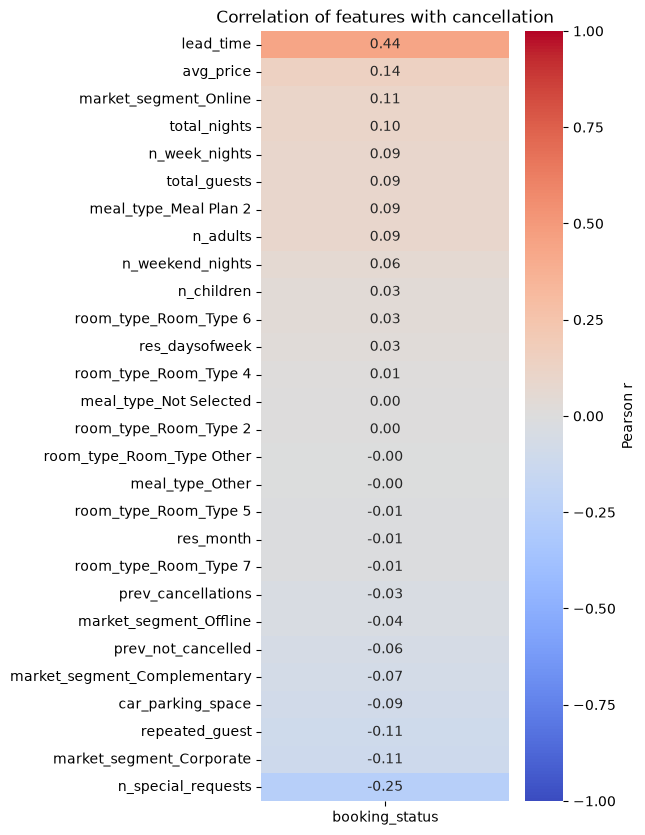

In [87]:
# Heatmap
plt.figure(figsize=(4, 10))
sns.heatmap(
    target_corr.to_frame(),
    annot=True, fmt=".2f",
    cmap="coolwarm", vmin=-1, vmax=1,
    cbar_kws={"label": "Pearson r"},
)
plt.title("Correlation of features with cancellation")
plt.show()

lead_time is the dominant correlation with the target (0.44). bookings made further in advance are much more likely to be cancelled.

n_special_requirements is strongest negative correlation (-0.25). Guests who ask for things have bigger commitment to the stay.

The fact that there's a mix of strength of correlations (but very few strong ones) favours tree based models that can combine weak and non-linear signals and interactions 

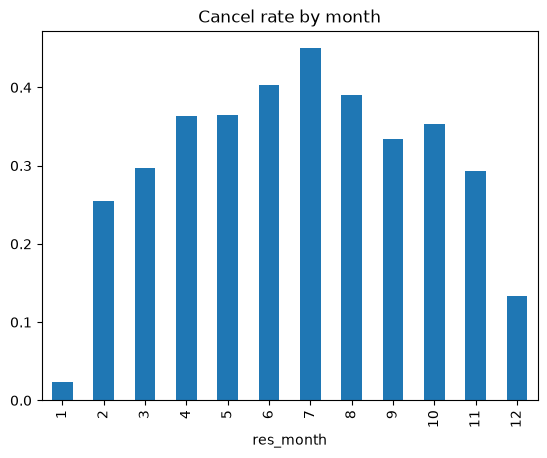

In [88]:
df.groupby("res_month")["booking_status"].mean().plot(kind="bar", title="Cancel rate by month"); plt.show()

res_month had correlation near 0 but seasonality isn't linear so Pearson can't capture it. Look at cancel rates by month.

There's clearly a seasonal hump around winter. January also only has 2018 data

## Split Data

In [89]:
from sklearn.model_selection import StratifiedGroupKFold

X = df.drop(columns="booking_status")
y = df["booking_status"]

# Identical rows (believed to be group bookings) get the same group
# ID so that they can't straddle train/test 
groups = pd.util.hash_pandas_object(X, index=False)

# 5 folds. Taking one fold as test gives an 80/20 split, stratified by target and grouped
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
train_idx, test_idx = next(sgkf.split(X, y, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print(f"Train: {len(X_train)} rows, cancel rate {y_train.mean():.3f}")
print(f"Test: {len(X_test)} rows, cancel rate {y_test.mean():.3f}")

Train: 28999 rows, cancel rate 0.328
Test: 7249 rows, cancel rate 0.328


In [ ]:
# To save splits for later scripts
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
X_train.assign(booking_status=y_train).to_csv(PROCESSED_DIR/"train.csv", index=False)
X_test.assign(booking_status=y_test).to_csv(PROCESSED_DIR/"test.csv", index=False)

## Modelling

In this case (hotel bookings) both false negatives (room goes empty at short notice because cancellation is missedm revenue lost) and false positives (guest who shows up flagged as likely cancellation, could lead to overbooking) are costly, so F1 for caneclled class is prioritised. ROC-AUC and PR-AUC measured alongside. Decision threshold will start at 0.5 but be tuned

In [90]:
# Create evaluation functions
import time
from sklearn.metrics import classification_report, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score

THRESHOLD = 0.5   
results = {}     

def evaluate(name, model, X_test, y_test, threshold=THRESHOLD, train_time=None):
    """
    Function to evaluate the performance of a model. Returns:
        - Precision 
        - Recall
        - F1
        - ROC-AUC
        - PR-AUC
        - Training time
        - Prediction time
    """
    start = time.time()
    proba = model.predict_proba(X_test)[:, 1]
    pred_time = time.time() - start
    y_pred = (proba >= threshold).astype(int)

    print(classification_report(y_test, y_pred, digits=3))
    results[name] = {
        "precision_1": precision_score(y_test, y_pred),
        "recall_1": recall_score(y_test, y_pred),
        "f1_1": f1_score(y_test, y_pred),
        "roc_auc": roc_auc_score(y_test, proba),
        "pr_auc": average_precision_score(y_test, proba),
        "train_time_s": train_time,
        "pred_time_s": pred_time,
    }
    return proba

def threshold_sweep(proba, y_test, thresholds=(0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60)):
    """
    Function to test different thresholds
    """
    print(f"{'Thresh':<8}{'Prec_1':<8}{'Rec_1':<8}{'F1_1':<8}")
    for t in thresholds:
        preds = (proba >= t).astype(int)
        print(f"{t:<8}{precision_score(y_test, preds):<8.3f}"
              f"{recall_score(y_test, preds):<8.3f}{f1_score(y_test, preds):<8.3f}")


### Logistic Regression

In [91]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

logreg = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42),
)
start = time.time(); logreg.fit(X_train, y_train); train_time = time.time() - start
proba_lr = evaluate("LogisticRegression", logreg, X_test, y_test, train_time=train_time)
threshold_sweep(proba_lr, y_test)

              precision    recall  f1-score   support

           0      0.870     0.784     0.825      4873
           1      0.632     0.760     0.690      2376

    accuracy                          0.776      7249
   macro avg      0.751     0.772     0.757      7249
weighted avg      0.792     0.776     0.781      7249

Thresh  Prec_1  Rec_1   F1_1    
0.3     0.517   0.912   0.660   
0.35    0.551   0.881   0.678   
0.4     0.575   0.843   0.684   
0.45    0.608   0.809   0.694   
0.5     0.632   0.760   0.690   
0.55    0.661   0.718   0.689   
0.6     0.679   0.685   0.682   


### Random Forest

In [92]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42, n_jobs=-1)
start = time.time(); rf.fit(X_train, y_train); train_time = time.time() - start
proba_rf = evaluate("RandomForest", rf, X_test, y_test, train_time=train_time)
threshold_sweep(proba_rf, y_test)

              precision    recall  f1-score   support

           0      0.873     0.868     0.871      4873
           1      0.733     0.741     0.737      2376

    accuracy                          0.827      7249
   macro avg      0.803     0.805     0.804      7249
weighted avg      0.827     0.827     0.827      7249

Thresh  Prec_1  Rec_1   F1_1    
0.3     0.634   0.884   0.738   
0.35    0.673   0.849   0.751   
0.4     0.691   0.797   0.740   
0.45    0.712   0.774   0.742   
0.5     0.733   0.741   0.737   
0.55    0.753   0.705   0.728   
0.6     0.773   0.665   0.715   


### LightGBM

In [93]:
from lightgbm import LGBMClassifier

lgbm = LGBMClassifier(n_estimators=500, learning_rate=0.05, class_weight="balanced",
                      random_state=42, n_jobs=-1, verbose=-1)
start = time.time(); lgbm.fit(X_train, y_train); train_time = time.time() - start
proba_lgbm = evaluate("LightGBM", lgbm, X_test, y_test, train_time=train_time)
threshold_sweep(proba_lgbm, y_test)

              precision    recall  f1-score   support

           0      0.906     0.846     0.875      4873
           1      0.722     0.821     0.768      2376

    accuracy                          0.837      7249
   macro avg      0.814     0.833     0.821      7249
weighted avg      0.846     0.837     0.840      7249

Thresh  Prec_1  Rec_1   F1_1    
0.3     0.619   0.925   0.742   
0.35    0.654   0.903   0.758   
0.4     0.682   0.876   0.767   
0.45    0.703   0.845   0.768   
0.5     0.722   0.821   0.768   
0.55    0.769   0.792   0.780   
0.6     0.784   0.753   0.768   


### XGBoost

In [94]:
from xgboost import XGBClassifier

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()   # ~2.0

xgb = XGBClassifier(n_estimators=500, learning_rate=0.05, max_depth=6, subsample=0.8,
                    colsample_bytree=0.8, scale_pos_weight=scale_pos_weight,
                    eval_metric="logloss", random_state=42, n_jobs=-1)
start = time.time(); xgb.fit(X_train, y_train); train_time = time.time() - start
proba_xgb = evaluate("XGBoost", xgb, X_test, y_test, train_time=train_time)
threshold_sweep(proba_xgb, y_test)

              precision    recall  f1-score   support

           0      0.897     0.849     0.872      4873
           1      0.720     0.801     0.758      2376

    accuracy                          0.833      7249
   macro avg      0.809     0.825     0.815      7249
weighted avg      0.839     0.833     0.835      7249

Thresh  Prec_1  Rec_1   F1_1    
0.3     0.617   0.918   0.738   
0.35    0.649   0.897   0.753   
0.4     0.672   0.846   0.749   
0.45    0.697   0.824   0.755   
0.5     0.720   0.801   0.758   
0.55    0.740   0.775   0.757   
0.6     0.757   0.748   0.753   


### Model Comparison

In [95]:
pd.DataFrame(results).T.round(3).sort_values("f1_1", ascending=False)

,precision_1,recall_1,f1_1,roc_auc,pr_auc,train_time_s,pred_time_s
LightGBM,0.722,0.821,0.768,0.927,0.878,2.237,0.070
XGBoost,0.720,0.801,0.758,0.921,0.868,1.308,0.013
RandomForest,0.733,0.741,0.737,0.902,0.831,0.923,0.087
LogisticRegression,0.632,0.760,0.690,0.859,0.757,0.092,0.003


### Feature Importance

Use this as a benchmark to check against EDA. Going with XGBoost since performance is similar to LightGBM but it is much faster.

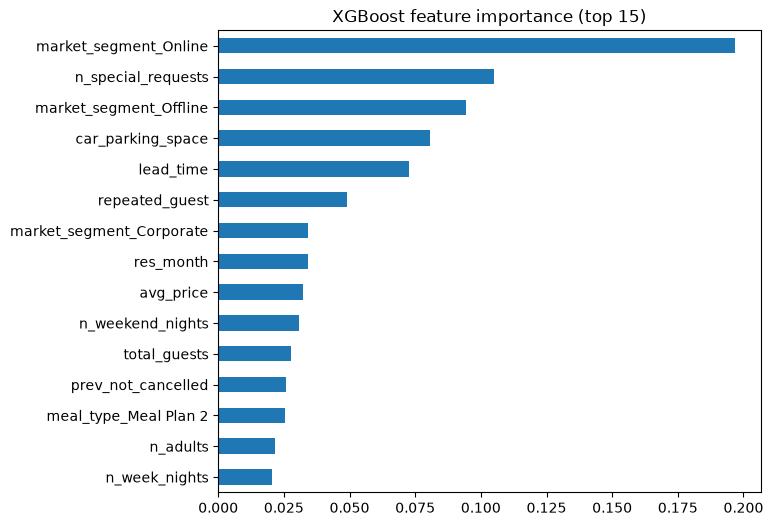

In [96]:
importances = pd.Series(xgb.feature_importances_, index=X_train.columns).sort_values()
importances.tail(15).plot(kind="barh", figsize=(7, 6), title="XGBoost feature importance (top 15)")
plt.show()

All of the features close to the top (segment, special requests, parking, lead time, repeated guest) were flagged in the EDA. There were no unexpected leads, and no signs of leakage. 

It is curious that lead_time is only 5th despite it's strong correlation with the target variable.

## Tuning

In [97]:
import optuna
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score
from xgboost import XGBClassifier

optuna.logging.set_verbosity(optuna.logging.WARNING)

scale_pos_weight = (y_train == 0).sum()/(y_train == 1).sum()
groups_train = groups.iloc[train_idx]
cv = StratifiedGroupKFold(n_splits = 5, shuffle=True, random_state = 42)

def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 300, 1000),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        "max_depth": trial.suggest_int("max_depth", 3, 10),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "gamma": trial.suggest_float("gamma", 0, 5),
        "reg_alpha": trial.suggest_float("reg_alpha", 0, 5),
        "reg_lambda": trial.suggest_float("reg_lambda", 0, 5),
        "scale_pos_weight": scale_pos_weight,
        "eval_metric": "logloss",
        "random_state": 42,
        "n_jobs": -1,
    }
    model = XGBClassifier(**params)
    scores = cross_val_score(model, X_train, y_train, groups=groups_train,
                         cv=cv, scoring="f1")
    return scores.mean()

study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective, n_trials=30, show_progress_bar=True)

print("Best params:", study.best_params)
print("Best CV F1:", round(study.best_value, 3))

  0%|          | 0/30 [00:00<?, ?it/s]

Best params: {'n_estimators': 499, 'learning_rate': 0.17059654454482737, 'max_depth': 8, 'subsample': 0.9852723309054048, 'colsample_bytree': 0.8909947527609061, 'min_child_weight': 3, 'gamma': 0.2154912145641944, 'reg_alpha': 2.7540722431125015, 'reg_lambda': 3.2011109711614147}
Best CV F1: 0.781


Refir best model on full training set and evaluate on test once

In [98]:
best_params = study.best_params | {
    "scale_pos_weight": scale_pos_weight,
    "eval_metric": "logloss",
    "random_state": 42,
    "n_jobs": -1,
}

xgb_tuned = XGBClassifier(**best_params)

start = time.time(); xgb_tuned.fit(X_train, y_train); train_time = time.time() - start

proba_tuned = evaluate("XGBoost_tuned", xgb_tuned, X_test, y_test,
                       threshold=THRESHOLD, train_time=train_time)

threshold_sweep(proba_tuned, y_test)

              precision    recall  f1-score   support

           0      0.896     0.845     0.870      4873
           1      0.715     0.798     0.754      2376

    accuracy                          0.830      7249
   macro avg      0.806     0.822     0.812      7249
weighted avg      0.837     0.830     0.832      7249

Thresh  Prec_1  Rec_1   F1_1    
0.3     0.630   0.888   0.737   
0.35    0.653   0.870   0.746   
0.4     0.679   0.850   0.755   
0.45    0.691   0.822   0.750   
0.5     0.715   0.798   0.754   
0.55    0.741   0.778   0.759   
0.6     0.757   0.754   0.755   


Compare with the untuned models

In [99]:
pd.DataFrame(results).T.round(3).sort_values("f1_1", ascending=False)

,precision_1,recall_1,f1_1,roc_auc,pr_auc,train_time_s,pred_time_s
LightGBM,0.722,0.821,0.768,0.927,0.878,2.237,0.070
XGBoost,0.720,0.801,0.758,0.921,0.868,1.308,0.013
XGBoost_tuned,0.715,0.798,0.754,0.920,0.865,1.305,0.013
RandomForest,0.733,0.741,0.737,0.902,0.831,0.923,0.087
LogisticRegression,0.632,0.760,0.690,0.859,0.757,0.092,0.003


See what the tuning did

C:\Users\charl\AppData\Local\Temp\ipykernel_37736\544031376.py:3: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  plot_optimization_history(study); plt.show()


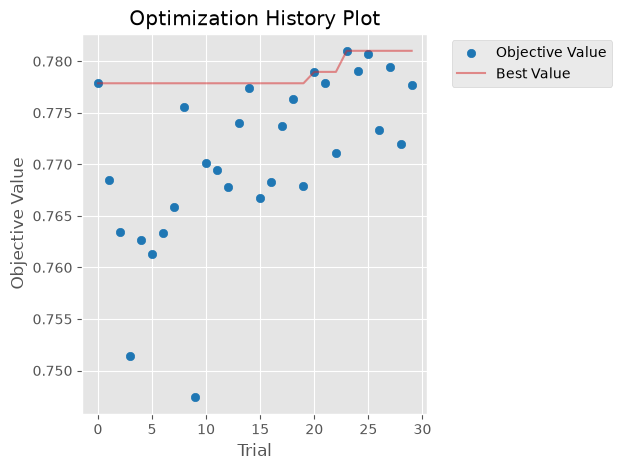

C:\Users\charl\AppData\Local\Temp\ipykernel_37736\544031376.py:4: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  plot_param_importances(study); plt.show()


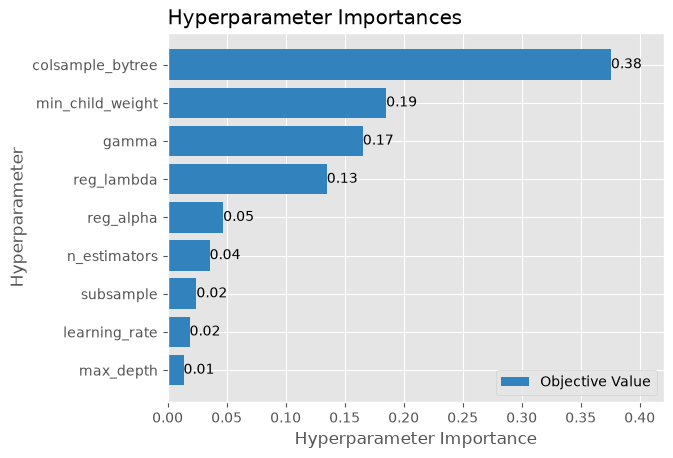

In [100]:
from optuna.visualization.matplotlib import plot_optimization_history, plot_param_importances

plot_optimization_history(study); plt.show()
plot_param_importances(study); plt.show()

## Conclusions